# DeepAgents 실습: 메모 파일 쓰기에 사람 승인을 켜고 끄기

**이 노트북에서 할 일**

1. 앞 절에서 배운 파일 도구·사람 승인·요청 수 셈을, 안내 메모를 파일에 적는 에이전트 하나에 모읍니다.
2. 사람 승인을 켠 실행 1과, 그 설정 하나만 끈 실행 2를 차례로 실행합니다.
3. 멈춘 자리와 메모 파일이 생긴 때, 요청 수를 두 실행에서 견줍니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 실행 1과 실행 2에서 에이전트를 한 번씩 실행합니다.
노트북 밖에서 두 실행을 다섯 번씩 보냈을 때, 요청은 열 번 모두 실행마다 2번이었습니다.
그래서 이 노트북의 모델 요청은 모두 4번으로 어림합니다.
호출 한도는 메모 에이전트 10, general-purpose 2로 줍니다.

요금표로 어림한 예상 비용은 두 실행을 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.
파일은 상태 칸 `files`에만 두고, 디스크에는 쓰지 않습니다.
멈춘 자리는 메모리에 두는 체크포인터 `InMemorySaver`에 저장합니다.
모델이 쓴 메모 글과 답 글은 실행마다 달라질 수 있습니다.
걸린 시간은 재지 않았습니다.

앞에서 배운 함수 다섯은 도구 파일 `harness_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 deepagents 0.7.0, langchain 1.4.0, langgraph 1.2.11입니다.
나머지 둘은 `langchain-openai` 1.6.0과 `python-dotenv` 1.2.3입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**실습 범위** — 이 절은 이 챕터의 실습이고, 30분 안팎입니다.
따로 내는 과제는 없고, 강사와 함께 첫 셀부터 차례로 실행합니다.

실습 폴더 `labs/part6/ch27-deepagents`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 맨 위에 초록 상자 셋이 나란히 있습니다. 01~03절 안전 규칙 바깥 호출 한도 10 general-purpose 한도 2, 04절 파일 도구가 적을 곳 메모 파일 /reports/notice.md 요청 글은 07절 자료, 08절 사람 승인 approval 실행 1 write_file True 실행 2 빈 딕셔너리입니다. 세 상자에서 파란 상자 build_memo_agent create_deep_agent에 넘김 새 InMemorySaver로 화살표가 모입니다. 거기서 실행 1과 실행 2라고 적힌 점선이 노란 상자 둘로 갈립니다. 실행 1 에이전트 노드 여덟 도구 아홉 HumanInTheLoopMiddleware.after_model 있음과, 실행 2 에이전트 노드 일곱 도구 아홉 승인 노드 없음입니다. 두 노란 상자에서 실행 결과라고 적힌 화살표가 맨 아래 파란 상자 show_run 요청 수 sum_usage 파일 위치 call_args로 모이는 그림](attachment:09-1-메모-에이전트의-조립.png)

위에서 아래로 읽습니다.
초록 상자는 이 절에서 정한 값이고, 파란 상자는 이 노트북에 적은 함수입니다.
노란 상자는 노트북 3절 둘째 셀과 6절 첫 셀 출력으로 확인한 값입니다.
점선은 승인 설정 값에 따라 갈리는 두 실행입니다.
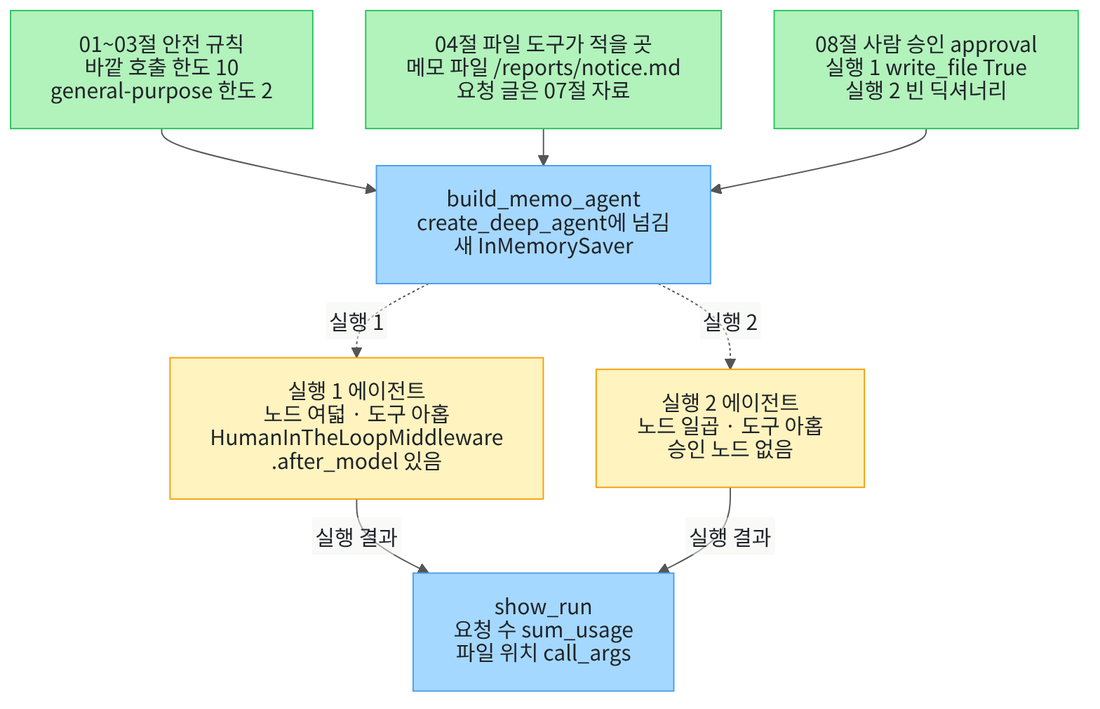

## 1. 준비

이 절은 Ch 27의 실습입니다.
01~08절에서 하나씩 본 기능 가운데 셋을, 안내 메모를 파일에 적는 에이전트 하나에 모읍니다.
04절의 파일 도구와 상태 칸, 08절의 사람 승인, 02절부터 쓴 요청 수 셈입니다.
그다음 사람 승인 설정 하나만 바꿔 두 번 실행하고, 두 결과를 견줍니다.

첫 셀은 패키지 다섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "deepagents==0.7.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("deepagents:", version("deepagents"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
deepagents: 0.7.0
langchain: 1.4.0
langchain-openai: 1.6.0


langgraph: 1.2.11
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `deepagents: 0.7.0`과 `langgraph: 1.2.11`이 보입니다.
다섯 판 모두 실습 폴더 잠금과 같은 판입니다.
패키지 langgraph는 체크포인터와 이어 가기의 `Command`를 가져오려고 넣었습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
마지막 가져오기 줄은 앞에서 배운 함수 다섯을 도구 파일 `harness_tools.py`에서 가져옵니다.

In [2]:
# Deep Agents(01절)·호출 한도(Ch 22)·모델·메시지·체크포인터(Ch 23)·Command(Ch 24) 이름을 가져옵니다
from deepagents import create_deep_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command
# 앞 챕터와 01·07절에서 배운 함수 다섯은 도구 파일에서 가져옵니다
from harness_tools import call_args, estimate_cost, show_messages, sum_usage, tool_names

print("도구 파일에서 가져온 함수:", "call_args, estimate_cost, show_messages, sum_usage, tool_names")

도구 파일에서 가져온 함수: call_args, estimate_cost, show_messages, sum_usage, tool_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: call_args, estimate_cost, show_messages, sum_usage, tool_names`가 보입니다.
네 함수 `estimate_cost`·`show_messages`·`sum_usage`·`tool_names`의 뜻은 02절 1절에 적었습니다.
함수 `call_args`는 07절에서 처음 만든 함수이고, 도구 요청에서 인자 값 하나를 모읍니다.
08절에서 07절 셀 글 그대로 도구 파일에 옮겨 두었습니다.

앞에서 배운 함수는 `harness_tools.py`에 모아 두었고, 파일을 열면 코드를 볼 수 있습니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
가져온 이름은 모두 08절에서 쓴 이름이고, 이 절에서 새로 배우는 이름은 없습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 5절과 6절의 실행 셀, 5절의 이어 가기 셀에서만 나갑니다.

## 2. 재료와 안전 규칙

01절 안전 규칙대로, 모델을 부르는 에이전트에는 두 한도를 넣습니다.
다음 셀은 02절 셀과 같은 글의 general-purpose 명세입니다.

In [5]:
# 기본 서브에이전트와 같은 이름의 명세를 만들고, 그 안에 자기 호출 한도 둘을 넣습니다(01절 6절 모양)
helper_limit = ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")
helper_spec = {
    "name": "general-purpose",
    "description": "교재용 도우미입니다. 맡긴 일을 짧게 처리합니다.",
    "system_prompt": "맡긴 일을 두 문장의 한국어로 처리하세요.",
    "middleware": [helper_limit],
}
print("명세의 키:", list(helper_spec))

명세의 키: ['name', 'description', 'system_prompt', 'middleware']


**결과 읽기** — 출력 줄 `명세의 키: ['name', 'description', 'system_prompt', 'middleware']`가 보입니다.
이 명세는 기본 general-purpose 서브에이전트의 자리를 바꾸고, 자기 호출 한도 2를 갖습니다.
모델이 `task`를 부르면, 한 번 부를 때마다 요청이 두 번까지만 나갑니다.

다음 셀은 03절 셀과 같은 글의 바깥 호출 한도입니다.

In [6]:
# 바깥 에이전트의 모델 요청을 열 번까지로 막는 호출 한도를 만듭니다(02절 셀과 한도만 다름)
outer_limit = ModelCallLimitMiddleware(run_limit=10, exit_behavior="end")
print("바깥 호출 한도:", outer_limit.run_limit)

바깥 호출 한도: 10


**결과 읽기** — 출력 줄 `바깥 호출 한도: 10`이 보입니다.
주석의 「02절 셀과 한도만 다름」은 이 셀을 처음 쓴 03절에서 적은 말입니다.
이 한도는 invoke 한 번 안의 모델 요청 수를 셉니다.
08절에서 본 것처럼, 승인으로 멈췄다가 이어 가면 이어 간 invoke에서 다시 0부터 셉니다.

다음 셀은 두 실행에 같게 쓸 글과 설정을 실행 전에 정합니다.
요청 글은 07절 교재용 자료 가운데 무인 반납함 안내의 두 문장에, 머리말 「안내 글:」만 붙인 글입니다.
실제 기관의 글이 아니라, 흐름을 보여 주려고 정한 예입니다.

In [7]:
# 두 실행에 같게 쓸 메모 파일 위치·시스템 메시지 글·요청 글·스레드 설정을 실행 전에 정하고 출처와 함께 출력합니다
memo_path = "/reports/notice.md"
memo_text = "사용자가 보낸 안내 글을 자료실 이용자에게 보낼 한국어 한 문장으로 다듬으세요. 다듬은 문장은 write_file로 /reports/notice.md에 적으세요. write_file 말고 다른 도구는 쓰지 마세요. 파일에 적은 뒤에는 파일을 다시 읽지 말고, 적은 파일 위치를 한 문장으로 알려 주세요."
request_text = "안내 글: 자료실 정문 옆 무인 반납함은 휴관일에도 쓸 수 있습니다. 반납함에 넣은 책은 다음 운영일에 반납 처리됩니다."
run_config = {"configurable": {"thread_id": "memo-run"}}
print("메모 파일 위치:", memo_path)
print("요청 글:", request_text)
print("요청 글의 출처: 07절 교재용 자료 /sources/return-box.md의 두 문장")

메모 파일 위치: /reports/notice.md
요청 글: 안내 글: 자료실 정문 옆 무인 반납함은 휴관일에도 쓸 수 있습니다. 반납함에 넣은 책은 다음 운영일에 반납 처리됩니다.
요청 글의 출처: 07절 교재용 자료 /sources/return-box.md의 두 문장


**결과 읽기** — 출력 줄 `메모 파일 위치: /reports/notice.md`가 보입니다.
라벨 `요청 글:` 뒤에는 모델에게 보낼 공지 글이, 라벨 `요청 글의 출처:` 뒤에는 그 글을 가져온 곳이 보입니다.
시스템 메시지 글은 공지 글을 한 문장으로 다듬어 이 파일에 적고, 다른 도구는 쓰지 말라고 정합니다.
머리말 「안내 글:」과 시스템 메시지 글 속 「안내 글」은 이 공지 글을 가리키고, 05절의 안내 글과 다릅니다.

적은 뒤 파일을 다시 읽지 말라는 말도 넣었습니다.
08절 노트북 밖 확인에서, 이어 간 뒤 방금 적은 보고 파일을 다시 읽은 실행이 있었기 때문입니다.
스레드 설정 `run_config`는 두 실행에 같게 씁니다.

## 3. 조립하기

조립에는 앞 절의 기능 셋을 씁니다.
04절의 파일 도구가 메모를 상태 칸 `files`에 적고, 08절의 사람 승인이 그 쓰기 앞에서 멈춥니다.
두 실행의 결과는 02절부터 쓴 요청 수 셈으로 셉니다.

다음 셀은 사람 승인 설정 하나를 인자로 받아 에이전트를 만드는 조립 함수입니다.
08절 3절 조립에서 권한 규칙을 빼고, 인자 `interrupt_on=`의 값을 바깥에서 받게 했습니다.

In [8]:
# 사람 승인 설정 하나를 받아, 메모 에이전트를 새 체크포인터와 함께 만들어 내놓습니다(08절 3절 조립에서 권한 규칙을 뺀 모양)
def build_memo_agent(approval):
    # 01절 안전 규칙: 바깥 호출 한도(가)와 같은 이름 general-purpose 명세(나)를 늘 함께 넘깁니다
    return create_deep_agent(
        model=model,
        system_prompt=memo_text,
        middleware=[outer_limit],
        subagents=[helper_spec],
        interrupt_on=approval,
        checkpointer=InMemorySaver(),
    )

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수는 부를 때마다 새 체크포인터 `InMemorySaver`를 만들어 넘깁니다.
그래서 두 실행이 같은 스레드 이름을 써도, 기록은 에이전트마다 따로 남습니다.
모델·시스템 메시지 글·두 한도는 앞 셀에서 만든 이름을 그대로 씁니다.

다음 셀은 실행 1의 에이전트를 만듭니다.
사람 승인 설정은 08절과 같은 `{"write_file": True}`입니다.

In [9]:
# 실행 1의 에이전트: 사람 승인을 켜서(write_file 앞에서 멈춤) 만들고, 노드 이름과 도구 수를 봅니다(요청은 아직 보내지 않음)
first_agent = build_memo_agent({"write_file": True})
first_graph = first_agent.get_graph()
print("노드:", list(first_graph.nodes))
print("승인 노드가 있는가:", "HumanInTheLoopMiddleware.after_model" in first_graph.nodes)
first_tools = tool_names(first_agent)
print("도구 수:", len(first_tools))

노드: ['__start__', 'model', 'tools', 'PatchToolCallsMiddleware.before_agent', 'ModelCallLimitMiddleware.before_model', 'ModelCallLimitMiddleware.after_model', 'HumanInTheLoopMiddleware.after_model', '__end__']
승인 노드가 있는가: True
도구 수: 9


**결과 읽기** — 출력 줄 `승인 노드가 있는가: True`와 `도구 수: 9`가 보입니다.
라벨 `노드:` 뒤에는 노드 이름 여덟이 있습니다.
08절 3절에서 본 것처럼, 사람 승인은 노드 `HumanInTheLoopMiddleware.after_model` 하나로 붙었습니다.
권한 규칙은 노드를 더하지 않으므로, 08절 보고 에이전트와 노드 이름이 같습니다.
이 셀까지 모델 요청은 0번입니다.

## 4. 두 실행을 견줄 함수

두 실행을 같은 잣대로 견주려고, 결과에서 볼 값을 한 줄로 출력하는 함수를 먼저 적습니다.
함수 `show_run`은 첫 invoke 결과와, 넣은 요청 글 뒤에 실행이 더한 메시지를 받습니다.
첫 invoke에서 멈췄는지와 그때 메모 파일이 있었는지는 첫 결과로 봅니다.
도구 `write_file`에 넣은 파일 위치와 요청 수는 더한 메시지로 셉니다.

In [10]:
# 실행 이름과 첫 invoke 결과, 실행이 더한 메시지를 받아 두 실행을 견줄 값을 한 줄로 출력하고 사용량을 내놓습니다
def show_run(label, first, new_messages):
    usage = sum_usage(new_messages)
    paused = "__interrupt__" in first
    memo_first = memo_path in first["files"]
    # 도구 write_file에 넣은 파일 위치를 모읍니다(07절 함수 call_args)
    writes = call_args(new_messages, "write_file", "file_path")
    print(label, "|", paused, "|", memo_first, "|", writes, "|", usage["requests"])
    return usage

**결과 읽기** — 정의 셀이라 출력이 없습니다.
요청 수는 02절에서 본 것처럼 더한 메시지의 `AIMessage` 수이고, Ch 19 05절 함수 `sum_usage`가 셉니다.
파일 위치는 07절 함수 `call_args`로 모읍니다.
이 함수는 사용량 딕셔너리를 내놓아, 7절에서 예상 비용을 셀 때 씁니다.

## 5. 실행 1: 사람 승인을 켠 실행

이제 실행 1을 합니다.
요청 글 한 줄을 실행 1의 에이전트에 넣습니다.
실행 전에 예상해 봅니다.
모델이 `write_file`을 요청하면 첫 invoke는 어디서 멈추고, 그때 메모 파일은 상태 칸에 있을까요?

In [11]:
# 실행 1: 요청 글 한 줄을 넣어 실행합니다(모델이 write_file을 요청하면 승인 자리에서 멈춤)
first_input = {"messages": [HumanMessage(content=request_text)]}
input_count = len(first_input["messages"])
first_result = first_agent.invoke(first_input, run_config)
print("멈췄는가:", "__interrupt__" in first_result)
print("첫 invoke 뒤 메모 파일이 있는가:", memo_path in first_result["files"])

멈췄는가: True
첫 invoke 뒤 메모 파일이 있는가: False


**결과 읽기** — 라벨 `멈췄는가:` 뒤의 값으로, 첫 invoke가 승인 자리에서 멈췄는지 봅니다.
라벨 `첫 invoke 뒤 메모 파일이 있는가:` 뒤의 값으로, 그때 상태 칸에 메모 파일이 있는지 봅니다.
승인 노드는 모델 응답 뒤, 도구가 실행되기 전에 돕니다.

이번 실행에서는 `멈췄는가: True`, `첫 invoke 뒤 메모 파일이 있는가: False`였습니다.
모델이 첫 응답에서 `write_file`을 요청했고, 그 도구가 실행되기 전에 승인 노드에서 멈췄습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았습니다.

다음 셀은 멈춘 도구 요청을 보고, 요청마다 승인 결정 하나를 목록에 붙입니다.
08절 6절 셀에 쓰려는 글을 담고 출력하는 줄 셋을 더하고, 첫 줄 주석을 바꾼 글입니다.
사람은 이 글을 보고 승인할지 고릅니다.

In [12]:
# 멈춘 도구 요청마다 파일 위치와 쓰려는 글을 보고, 승인 결정 하나를 목록에 붙입니다(사람의 답 자리에 코드가 넣는 값)
decisions = []
paused_text = ""
if "__interrupt__" in first_result:
    paused_value = first_result["__interrupt__"][0].value
    for action in paused_value["action_requests"]:
        print("멈춘 도구 요청:", action["name"], "|", action["args"]["file_path"])
        paused_text = action["args"]["content"]
        print("쓰려는 글:", paused_text)
        decisions.append({"type": "approve"})
print("넣을 결정 수:", len(decisions))

멈춘 도구 요청: write_file | /reports/notice.md
쓰려는 글: 자료실 정문 옆 무인 반납함은 휴관일에도 이용할 수 있으며, 반납함에 넣은 책은 다음 운영일에 반납 처리됩니다.
넣을 결정 수: 1


**결과 읽기** — 라벨 `멈춘 도구 요청:` 뒤에 도구 이름과 파일 위치가 보입니다.
라벨 `쓰려는 글:` 뒤에는 모델이 파일에 적으려는 글이 보입니다.
라벨 `넣을 결정 수:` 뒤에는 결정 목록의 길이가 보이고, 멈춘 도구 요청 수와 같게 만들었습니다.
08절처럼, 이 노트북에서 사람의 답은 셀이 모든 요청에 넣는 승인입니다.
실제로는 이 자리에서 사람이 쓰려는 글을 읽고 결정을 고릅니다.

이번 실행에서는 `멈춘 도구 요청: write_file | /reports/notice.md`, `넣을 결정 수: 1`이었습니다.
모델은 시스템 메시지 글이 정한 파일 위치에 쓰려 했고, 노트북 밖 다섯 번과 새 커널 두 번에서도 같았습니다.
쓰려는 글은 공지 글 두 문장을 한 문장으로 이은 글이었습니다.
노트북 밖 다섯 번 가운데 한 번은 이 글이 조금 달랐습니다.

다음 셀은 결정 목록으로 같은 스레드를 이어 갑니다.

In [13]:
# 결정이 있으면 결정 목록으로 같은 스레드를 이어 가고, 없으면 첫 결과를 그대로 씁니다(08절 6절 셀과 같은 모양)
first_final = first_result
if len(decisions) > 0:
    first_final = first_agent.invoke(Command(resume={"decisions": decisions}), run_config)
print("다시 멈췄는가:", "__interrupt__" in first_final)
print("결과 메시지 수:", len(first_final["messages"]))

다시 멈췄는가: False
결과 메시지 수: 4


**결과 읽기** — 라벨 `다시 멈췄는가:`와 `결과 메시지 수:` 뒤에 값이 하나씩 보입니다.
결과 메시지는 멈추기 전 메시지에 이어 붙은, 스레드 전체의 목록입니다.

이번 실행에서는 `다시 멈췄는가: False`, `결과 메시지 수: 4`였습니다.
멈추기 전의 요청 글과 `write_file` 요청 응답에, 도구 메시지와 마지막 답이 더해졌습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았고, 이어 간 뒤 메모 파일을 다시 읽은 실행은 없었습니다.

다음 셀은 Ch 19 06절 함수 `show_messages`로 실행 1의 결과 메시지를 차례로 봅니다.

In [14]:
# 실행 1의 결과 메시지를 차례로 봅니다(Ch 19 06절 함수 show_messages)
print("실행 1 결과 메시지:")
show_messages(first_final["messages"])

실행 1 결과 메시지:
HumanMessage
AIMessage | 도구 호출 요청: ['write_file']
ToolMessage | 결과 상태: success | 내용: Updated file /reports/notice.md
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 아래가 실행 1 결과 메시지의 차례입니다.
`AIMessage` 줄에는 모델이 요청한 도구 이름이, `ToolMessage` 줄에는 결과 상태와 도구가 낸 글이 보입니다.
마지막 `AIMessage` 줄은 도구 요청이 없는 응답이고, 모델이 쓴 답입니다.

이번 실행에서 모델은 첫 응답에서 `write_file` 하나를 요청했고, 이어 간 뒤 도구 요청 없이 답했습니다.
도구 메시지의 결과 상태는 `success`였습니다.
이 차례는 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

다음 셀은 실행 뒤 메모 파일의 글이, 멈췄을 때 요청에 실려 있던 글과 같은지 봅니다.

In [15]:
# 메모 파일이 있으면 그 글을 보고, 멈췄을 때 요청에 실려 있던 글과 같은지 봅니다
if memo_path in first_final["files"]:
    first_memo = first_final["files"][memo_path]["content"]
    print("메모 파일의 글:", first_memo)
    print("멈춘 요청의 글과 같은가:", first_memo == paused_text)

메모 파일의 글: 자료실 정문 옆 무인 반납함은 휴관일에도 이용할 수 있으며, 반납함에 넣은 책은 다음 운영일에 반납 처리됩니다.
멈춘 요청의 글과 같은가: True


**결과 읽기** — 라벨 `메모 파일의 글:` 뒤에 상태 칸에 적힌 글이 보입니다.
라벨 `멈춘 요청의 글과 같은가:` 뒤의 값으로, 승인한 글이 그대로 적혔는지 봅니다.
결정 `approve`는 멈춘 요청을 고치지 않고 그대로 실행합니다.
메모 파일이 없으면 이 셀은 아무것도 출력하지 않습니다.

이번 실행에서는 `멈춘 요청의 글과 같은가: True`였습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 모두 `True`였습니다.
메모 글 자체는 모델이 쓴 글이라 실행마다 달라질 수 있습니다.

## 6. 실행 2: 사람 승인을 끈 실행

실행 2는 값 하나만 바꿉니다.
조립 함수에 넘기는 사람 승인 설정을 빈 딕셔너리 `{}`로 줍니다.
시스템 메시지 글·요청 글·한도·명세·스레드 이름은 실행 1과 같습니다.
설치판 `graph.py` 193~194행에서, 이 설정이 비어 있고 권한 규칙도 없으면 사람 승인 미들웨어를 붙이지 않습니다.
다음 셀은 실행 2의 에이전트를 만들고 노드를 봅니다.

In [16]:
# 실행 2의 에이전트: 값 하나만 바꿉니다. 사람 승인 설정을 빈 딕셔너리로 주고, 노드 이름과 도구 수를 봅니다
second_agent = build_memo_agent({})
second_graph = second_agent.get_graph()
print("노드:", list(second_graph.nodes))
print("승인 노드가 있는가:", "HumanInTheLoopMiddleware.after_model" in second_graph.nodes)
second_tools = tool_names(second_agent)
print("도구 수:", len(second_tools))

노드: ['__start__', 'model', 'tools', 'PatchToolCallsMiddleware.before_agent', 'ModelCallLimitMiddleware.before_model', 'ModelCallLimitMiddleware.after_model', '__end__']
승인 노드가 있는가: False
도구 수: 9


**결과 읽기** — 출력 줄 `승인 노드가 있는가: False`와 `도구 수: 9`가 보입니다.
라벨 `노드:` 뒤에는 노드 이름 일곱이 있습니다.
실행 1과 견주면 `HumanInTheLoopMiddleware.after_model`만 빠졌고, 도구와 호출 한도 노드는 그대로입니다.
이 셀도 에이전트를 만들기만 해서, 모델 요청은 나가지 않았습니다.

다음 셀은 실행 1과 같은 요청 글을 실행 2의 에이전트에 넣습니다.
실행 전에 예상해 봅니다.
승인 노드가 없으면, 첫 invoke가 끝났을 때 메모 파일은 상태 칸에 있을까요?
요청 수는 실행 1과 같을까요?

In [17]:
# 실행 2: 실행 1과 같은 요청 글을 넣어 실행합니다(체크포인터가 새것이라, 같은 스레드 이름이어도 새 기록)
second_input = {"messages": [HumanMessage(content=request_text)]}
second_result = second_agent.invoke(second_input, run_config)
print("멈췄는가:", "__interrupt__" in second_result)
print("첫 invoke 뒤 메모 파일이 있는가:", memo_path in second_result["files"])
print("결과 메시지 수:", len(second_result["messages"]))

멈췄는가: False
첫 invoke 뒤 메모 파일이 있는가: True
결과 메시지 수: 4


**결과 읽기** — 라벨 `멈췄는가:`와 `첫 invoke 뒤 메모 파일이 있는가:`, `결과 메시지 수:` 뒤에 값이 하나씩 보입니다.
멈추지 않았다면 이어 가지 않으므로, 이 결과가 실행 2의 마지막 결과입니다.

이번 실행에서는 `멈췄는가: False`, `첫 invoke 뒤 메모 파일이 있는가: True`, `결과 메시지 수: 4`였습니다.
승인 노드가 없어, 모델이 요청한 `write_file`이 첫 invoke 안에서 바로 실행되었습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았습니다.

다음 셀은 실행 2의 결과 메시지를 차례로 봅니다.

In [18]:
# 실행 2의 결과 메시지를 차례로 봅니다(Ch 19 06절 함수 show_messages)
print("실행 2 결과 메시지:")
show_messages(second_result["messages"])

실행 2 결과 메시지:
HumanMessage
AIMessage | 도구 호출 요청: ['write_file']
ToolMessage | 결과 상태: success | 내용: Updated file /reports/notice.md
AIMessage | 도구 호출 요청: []


**결과 읽기** — 라벨 줄 아래가 실행 2 결과 메시지의 차례입니다.
실행 1의 차례와 줄마다 견주어 봅니다.

이번 실행의 차례는 실행 1과 줄마다 같았습니다.
차례는 `write_file`을 요청한 응답, 결과 상태 `success`인 도구 메시지, 도구 요청 없는 답입니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았습니다.
실행 1과 다른 것은, 이 메시지들이 invoke 한 번 안에서 쌓였다는 점입니다.

다음 셀은 실행 2의 메모 파일 글을 봅니다.
이번에는 사람이 글을 보기 전에 파일에 적혔습니다.

In [19]:
# 메모 파일이 있으면, 사람의 승인 없이 적힌 그 글을 봅니다
if memo_path in second_result["files"]:
    second_memo = second_result["files"][memo_path]["content"]
    print("메모 파일의 글:", second_memo)

메모 파일의 글: 자료실 정문 옆 무인 반납함은 휴관일에도 이용할 수 있으며, 반납함에 넣은 책은 다음 운영일에 반납 처리됩니다.


**결과 읽기** — 라벨 `메모 파일의 글:` 뒤에 승인 없이 적힌 글이 보입니다.
메모 파일이 없으면 이 셀은 아무것도 출력하지 않습니다.

이번 실행의 메모 글은 실행 1의 글과 같았고, 새 커널 두 번째에서도 같았습니다.
다만 노트북 밖 다섯 번 가운데 한 번은 실행 1 조건의 글이 조금 달랐습니다.
그래서 두 실행의 글이 늘 같다고는 읽지 않습니다.

## 7. 두 실행 견주기

마지막으로 4절의 함수 `show_run`으로 두 실행을 한 줄씩 견줍니다.
두 실행 모두 넣은 요청 글 뒤, 실행이 더한 메시지만 잘라 넘깁니다.
실행 1은 멈추기 전과 이어 간 뒤의 메시지가 한 스레드에 쌓여 있어, 두 invoke를 함께 셉니다.

In [20]:
# 두 실행을 함수 show_run으로 한 줄씩 견줍니다(넣은 요청 글 뒤, 실행이 더한 메시지만 잘라 넘김)
first_new = first_final["messages"][input_count:]
second_new = second_result["messages"][input_count:]
print("실행 | 첫 invoke에서 멈췄는가 | 첫 invoke 뒤 메모 파일이 있는가 | write_file 파일 위치 | 요청 수")
first_usage = show_run("실행 1", first_result, first_new)
second_usage = show_run("실행 2", second_result, second_new)

실행 | 첫 invoke에서 멈췄는가 | 첫 invoke 뒤 메모 파일이 있는가 | write_file 파일 위치 | 요청 수
실행 1 | True | False | ['/reports/notice.md'] | 2
실행 2 | False | True | ['/reports/notice.md'] | 2


**결과 읽기** — 라벨 줄 아래 두 줄이 실행 1과 실행 2입니다.
칸은 왼쪽부터 첫 invoke에서 멈췄는가, 그때 메모 파일이 있었는가, 파일 위치, 요청 수입니다.

이번 실행에서는 `실행 1 | True | False | ['/reports/notice.md'] | 2`와 `실행 2 | False | True | ['/reports/notice.md'] | 2`였습니다.
두 실행 모두 같은 파일 위치에 썼고, 요청은 2번씩이었습니다.
요청 2번은 02절 셈대로, `write_file`을 요청한 응답 1과 답 1입니다.
노트북 밖 열 번과 새 커널 두 번에서 모두 같았습니다.

흔들림 확인 열 번과 두 커널에서 모두, 사람 승인은 요청 수를 늘리지 않았습니다.
이 결과는 다른 도구를 쓰지 말고, 적은 파일을 다시 읽지 말라고 정한 시스템 메시지 글 아래에서 얻은 것입니다.
실행 1의 요청 2번은 멈추기 전 하나, 이어 간 뒤 하나로 invoke 둘에 나뉘었습니다.
달라진 것은 메모 파일이 생긴 때입니다.
실행 1은 결정 목록을 넣은 뒤에, 실행 2는 첫 invoke 안에서 메모 파일이 생겼습니다.

마지막 셀은 두 실행의 토큰과 예상 비용을 봅니다.

In [21]:
# 두 실행의 토큰과 예상 비용을 봅니다(2026-09-17 요금표, 100만 토큰당 달러 — Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
first_cost = round(estimate_cost(first_usage, input_rate, cached_input_rate, output_rate), 6)
second_cost = round(estimate_cost(second_usage, input_rate, cached_input_rate, output_rate), 6)
print("실행 1 | 입력 토큰:", first_usage["input_tokens"], "| 출력 토큰:", first_usage["output_tokens"], "| 예상 비용(달러):", first_cost)
print("실행 2 | 입력 토큰:", second_usage["input_tokens"], "| 출력 토큰:", second_usage["output_tokens"], "| 예상 비용(달러):", second_cost)

실행 1 | 입력 토큰: 3913 | 출력 토큰: 78 | 예상 비용(달러): 0.003286
실행 2 | 입력 토큰: 3913 | 출력 토큰: 75 | 예상 비용(달러): 0.003272


**결과 읽기** — 줄마다 한 실행의 입력 토큰·출력 토큰과, 라벨 `예상 비용(달러):` 뒤의 어림값이 보입니다.
입력 토큰을 모두 입력 요금으로 센 어림이고, 청구 금액이 아닙니다.

이번 실행에서는 실행 1이 입력 3913·출력 78토큰으로 0.003286달러였습니다.
실행 2는 입력 3913·출력 75토큰으로 0.003272달러였습니다.
새 커널 두 번째는 출력 토큰이 서로 바뀌어, 실행 1이 75, 실행 2가 78이었습니다.
노트북 밖 열 번의 출력 토큰은 75 또는 76이었습니다.
출력 토큰의 차이는 모델이 쓴 글에서 나온 것이라, 두 실행의 비용 차이로 읽지 않습니다.

## 정리

1. 04절 파일 도구, 08절 사람 승인, 02절부터 쓴 요청 수 셈을 메모를 적는 에이전트 하나에 모았습니다.
2. 사람 승인 설정을 빈 딕셔너리로 바꾸자 승인 노드가 붙지 않았습니다. 이번 실행에서는 첫 invoke 안에서 메모 파일이 적혔습니다.
3. 승인을 켜면 멈춘 동안 메모 파일이 없고, 승인한 글이 그대로 적힙니다. 흔들림 확인 열 번과 두 커널에서 두 실행의 요청 수는 모두 2번이었습니다.

이 절로 Ch 27이 끝납니다.
Ch 28 01절에서는 도구를 같은 프로그램 밖의 서버로 옮겨, 여러 클라이언트가 같은 방식으로 찾게 하는 MCP를 봅니다.